# **Binary Integer Optimisation**

### 1. Theory 

In this notebook, we will formulate our satetille scheduling task into an optimisation problem; specifically an integer programming problem. Let us begin by definition all variables in our model. For a given ground station $G$, we have $N$ number of data transfer windows. Note that each window is not necessarily associated with a unique satellite. That is, the same satellite may contribute to multiple transfer windows depending on the time interval considered. $T$ is then the length of our time interval $[t_i, t_f]$. As an example, consider the following $N=5$ transfer windows,

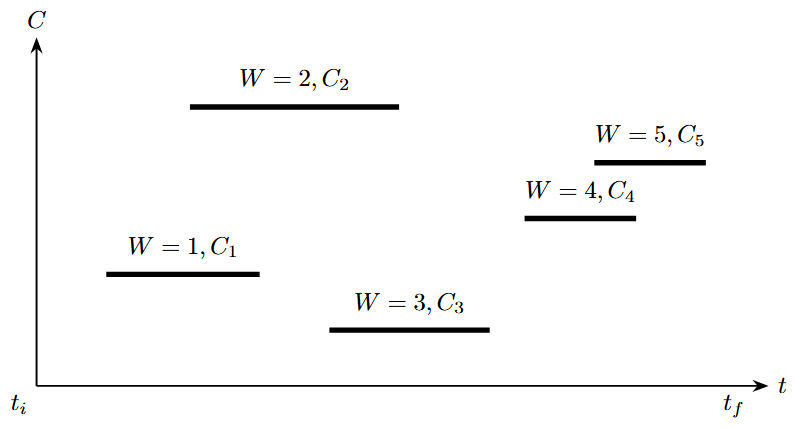

Each window $w$ has a capacity $c_w = R_wT_w$ that represents the maximum amount of data that can be downloaded by the ground station from it. Since many of the windows overlap and in our model a ground station can not use multiple windows simultaneously, a problem regarding which windows to choose arises when the objective is to maximise the amount of data downloaded over $T$. Following from this, we define the binary variables $x_w \in \{ 0, 1 \}$ for each window $w$ that represents whether or not the station uses them. The total data downloaded by the ground satellite $G$ over $T$ can then be written as the following linear function $f(\mathbf{x})$,

$$
f(\mathbf{x}) = c_1 x_1 + c_2 x_2 + \cdots + c_N x_N = \sum_{w=1}^{N} c_w x_w
$$

There should exist some selection of windows $\mathbf{x} = [x_1, x_2, ..., x_N]$ (column vector) for which $f(\mathbf{x})$ is maximised. Finding this $\mathbf{x}$ such that,

$$
\max_{\mathbf{x}}\sum_{w=1}^{N} c_w x_w
$$

is our optimisation problem. During $T$, we want to impose a hard limit on the amount of data downloaded $D$. This may be a file size for example. This creates the following constraint, 

$$
\sum_{w=1}^{N} c_w x_w \leq D
$$

We must also account for the constraints which arise from the ground station only being able to use a single transfer window at any time $t$. Let us say that a pair of transfer windows which the indices $(i, j)$ overlap. $\mathcal{O}$ is then the set of indice tuples that represent pairs of overlapping transfer windows. In the example given via the diagram, we have $\mathcal{O} = \{(1, 2), (2, 3), (4, 5)\}$. Each pair $(i, j)$ yields the following constraint,

$$
x_i + x_j \leq 1
$$

This enforces the condition that the $i$-th and $j$-th window cannot be taken at the same time. If both were to be taken simultaneously such that $x_i=1$ and $x_j=1$, then $x_i + x_j > 1$ which would violate the constraint. Now we can fully write out our optimisation problem,

$$
\boxed{
\begin{aligned}
\max_{\mathbf{x}} \quad & \mathbf{c}^T \mathbf{x} \\
\text{s.t.} \quad & \mathbf{c}^T \mathbf{x} \leq D \\
& x_w \in \{0,1\} \quad \forall \quad w = 1, 2, \ldots, N \\
& x_i + x_j \leq 1 \quad \forall \quad (i,j) \in \mathcal{O}
\end{aligned}
}
$$

where we have written $\mathbf{c}=[c_1, c_2, ..., c_N]$ and $\mathbf{x}=[x_1, x_2, ..., x_N]$ as a column vectors containing each window capacity and its decision variable respectively.

### General Optimisation Problem

We want to solve our optimisation problem using the `scipy.optimize.milp` method in SciPy. According to the documentation, the method solves the following mixed integer linear programming problem,

$$
\boxed{
\begin{aligned}
\min_{\mathbf{x}} \mathbf{c}^T \mathbf{x} \\
\text{s.t.} \quad & \mathbf{b_l} \geq A \mathbf{x} \geq \mathbf{b_u} \\
& l \leq \mathbf{x} \leq u \quad \forall \quad x \\
& x_i \in \mathcal{Z}, i \in X_i
\end{aligned}
}
$$

This is a more general optimisation than ours. Since our variables $x_i$ are binary, their upper and lower bounds are $l=0$ and $u=0$ respectively such that $0 \leq \mathbf{x} \leq 1$. The majority of our work is to rewrite our other constraints in terms of the matrix $A$ and vectors $\mathbf{b_l}$ and $\mathbf{b_u}$. Each condition will represent a row of the matrix and stacking these row vectors vertically forms $A$. For the constraint associated with the payload $\mathbf{c}^T \mathbf{x} \leq D$, we construct a row vector $N$ elements long where each element has the value `1`. Additionally, for each window overlap condition a row  

### 2. Basic Implementation

Let us now implement the solver,

In [1]:
# Dependencies,
import numpy as np
from scipy.optimize import milp
from scipy.optimize import LinearConstraint

# System parameters,
N = 5
overlaps = [(0, 1), (1, 2), (3, 4)]
window_lengths = [5, 8, 6, 3, 3]
download_rates = [10, 15, 5, 20, 25]
payload = 250

# Precomputation, 
c = -np.array(download_rates)*np.array(window_lengths)

# Initialising matrix and constucting bound vectors,
M = len(overlaps) + 1
A = np.zeros((M, N))
b_u = np.ones(M)
b_u[-1] = payload
b_l = np.full_like(b_u, -np.inf, dtype=float)

# Encoding overlaps,
for idx in range(M-1):
    i, j = overlaps[idx]
    A[idx][i] = 1
    A[idx][j] = 1

# Encoding payload constraint,
for idx in range(N):
    A[-1][idx] = download_rates[idx]*window_lengths[idx]

# Using the solver,
constraints = LinearConstraint(A, b_l, b_u)
integrality = np.ones_like(N)
res = milp(c=c, constraints=constraints, integrality=integrality, bounds=(0, 1))
x_sol = res.x.astype(int)
x_sol

array([0, 1, 0, 0, 1])

Now we wrap the solver inside a convenient method,

In [2]:
def milp_solver(overlaps, capacities, payload):
    """Solves the MILP problem for the given parameters."""

    c = -np.array(capacities)
    N = len(c)

    M = len(overlaps) + 1
    A = np.zeros((M, N))
    b_u = np.ones(M)
    b_u[-1] = payload
    b_l = np.full_like(b_u, -np.inf, dtype=float)

    for idx in range(M-1):
        i, j = overlaps[idx]
        A[idx][i] = 1
        A[idx][j] = 1

    for idx in range(N):
        A[-1][idx] = capacities[idx]

    constraints = LinearConstraint(A, b_l, b_u)
    integrality = np.ones_like(N)
    res = milp(c=c, constraints=constraints, integrality=integrality, bounds=(0, 1))
    sol = res.x.astype(int)
    
    return sol

### 3. Application to Satellite Constellation

Now that we have applied our MILP solver to our simple example, we move on to applying it to our toy system. We create our satellite system consisting of many satellites in concentric rings,

In [48]:
# Importing,
import numpy as np
from Scheduler import SatelliteSystem, Station, Satellite
from Utils import compute_overlaps

# Creating the system,
system = SatelliteSystem(planetary_radius=6000, planetary_mass=5.972e24, planetary_angular_velocity=7.2921159e-5)

# Adding ground stations,
station1 = Station(name="G1", position=np.pi/3)
station2 = Station(name="G2", position=2*np.pi/3)
station3 = Station(name="G3", position=4*np.pi/3)
system.add_station(station1)
system.add_station(station2)
system.add_station(station3)

# Adding satellites,
def create_ring(altitude, num_sats, label_prefix="SAT", orbit_prograde=True, transfer_rate=0, phase_offset=0):
    for i in range(num_sats):
        sat = Satellite(name=f"{label_prefix}-{i+1}", 
                        altitude=altitude, phase_angle=(2*np.pi*i/num_sats + phase_offset), 
                        orbit_prograde=orbit_prograde, 
                        transfer_rate=transfer_rate)
        system.add_sat(sat)

create_ring(altitude=500, num_sats=25, label_prefix="LEO-A", transfer_rate=250, phase_offset=np.pi/5, orbit_prograde=True)
create_ring(altitude=1000, num_sats=10, label_prefix="LEO-B", transfer_rate=100, phase_offset=np.pi/7, orbit_prograde=False)
create_ring(altitude=2000, num_sats=5, label_prefix="LEO-C", transfer_rate=25, phase_offset=np.pi/9, orbit_prograde=True)

We now calculate the transfer windows, extract the capacities, compute the overlaps and specify a payload,

In [59]:
windows = system.compute_windows(station=station1, interval=(0, 60*60), format=False, order=True) # 1 hour.
capacities = [w[4] for w in windows]
overlaps = compute_overlaps(windows)
payload = 0.75*10**6 # 0.75TB

Finally we can use our solver,

In [60]:
sol = milp_solver(overlaps, capacities, payload)
sol

array([0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

We view the schedule,

Payload Downloaded: 0.533 TB


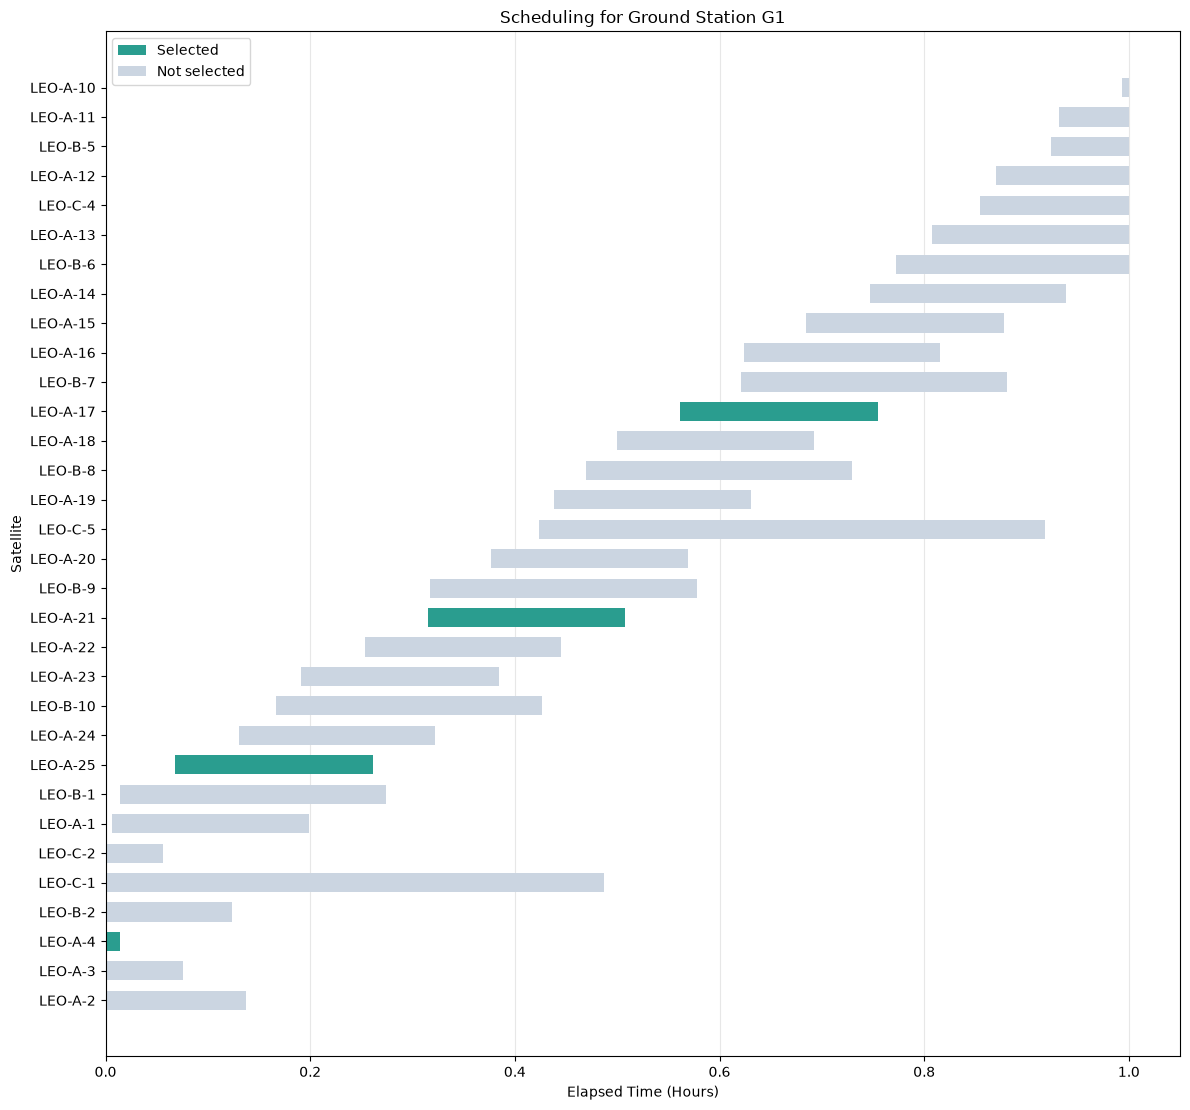

In [61]:
### GENERATED CODE GPT-6 LUNA VIA COPILOT

# Importing,
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Extracting selected windows,
selected_windows = []
for window, decision_var in zip(windows, sol):
    if decision_var == 1:
        selected_windows.append(window)

# Calculating payload downloaded,
payload_downloaded = np.array([w[4] for w in selected_windows]).sum()
print(f"Payload Downloaded: {round(payload_downloaded.item()/10**6, 3)} TB")

# Extracting satellite names and positions for plotting,
satellite_names = list(dict.fromkeys(window[0] for window in windows))
satellite_positions = {name: position for position, name in enumerate(satellite_names)}

# Plotting,
fig, ax = plt.subplots(figsize=(12, max(4, 0.35 * len(satellite_names))))

for window_idx, (satellite, start, end, _, _) in enumerate(windows):
    is_selected = sol[window_idx] == 1
    ax.barh(
        satellite_positions[satellite],
        (end - start) / 3600,
        left=start / 3600,
        height=0.65,
        color="#2a9d8f" if is_selected else "#cbd5e1",
    )

ax.set_yticks(list(satellite_positions.values()))
ax.set_yticklabels(satellite_names)
ax.set_xlabel("Elapsed Time (Hours)")
ax.set_ylabel("Satellite")
ax.set_title(f"Scheduling for Ground Station {station1.name}")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
ax.legend(handles=[
    Patch(facecolor="#2a9d8f", label="Selected"),
    Patch(facecolor="#cbd5e1", label="Not selected"),
])

fig.tight_layout()
plt.show()

### 4. Extending The Model

So far, we have only considered using the entire length of a transfer window once it is chosen. This leaves many times where the ground station is not downloading data between selected transfer windows. For this reason, we many want to extend the model to allow for partial windows. That is, once a transfer window is choosen by the station, it does not have to use it completely until it finishes. This would allow the stations to switch to better transfer windows while already using another. Instead of rewriting the optimisation problem, we will discretise the transfer windows into time steps of $\delta$. Essentially, we will have the same model but segment the windows. 

In [67]:
def create_window_segments(windows, delta):
    """Divide each window into smaller time segments."""

    window_segments = []
    for window_idx, window in enumerate(windows):
        start_time, end_time = window[1], window[2]
        total_capacity = window[4]
        times = np.arange(start=start_time, stop=end_time, step=delta)

        # Include the window's end time if it wasn't reached by the steps.
        if times[-1] != end_time:
            times = np.append(times, end_time)

        # Give each segment a unique source-window ID and segment number.
        for idx in range(len(times) - 1):
            start_t = times[idx].item()
            end_t = times[idx + 1].item()
            duration = end_t - start_t
            capacity = total_capacity / len(times)

            window_name = window[0]
            segment_name = f"{window_name}-s{idx + 1}"
            window_segments.append(
                (segment_name, start_t, end_t, duration, capacity)
            )

    return window_segments

Now we segment the windows before running them through the optimiser,

In [68]:
# Settings,
interval = (0, 60*60) # 1 hour.
delta = 30 # 1 minute.
payload = 0.5*10**6 # 0.75TB

# Calculating windows, overlaps and capacities,
windows = system.compute_windows(station=station1, interval=interval, format=False, order=True)
windows=create_window_segments(windows, delta=delta)
capacities = [w[4] for w in windows]
overlaps = compute_overlaps(windows)
payload = 0.75*10**6 # 0.5TB

# Solving the MILP problem,
sol = milp_solver(overlaps, capacities, payload)
sol

array([0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0,

Graphing the results,

Payload Downloaded: 0.75 TB


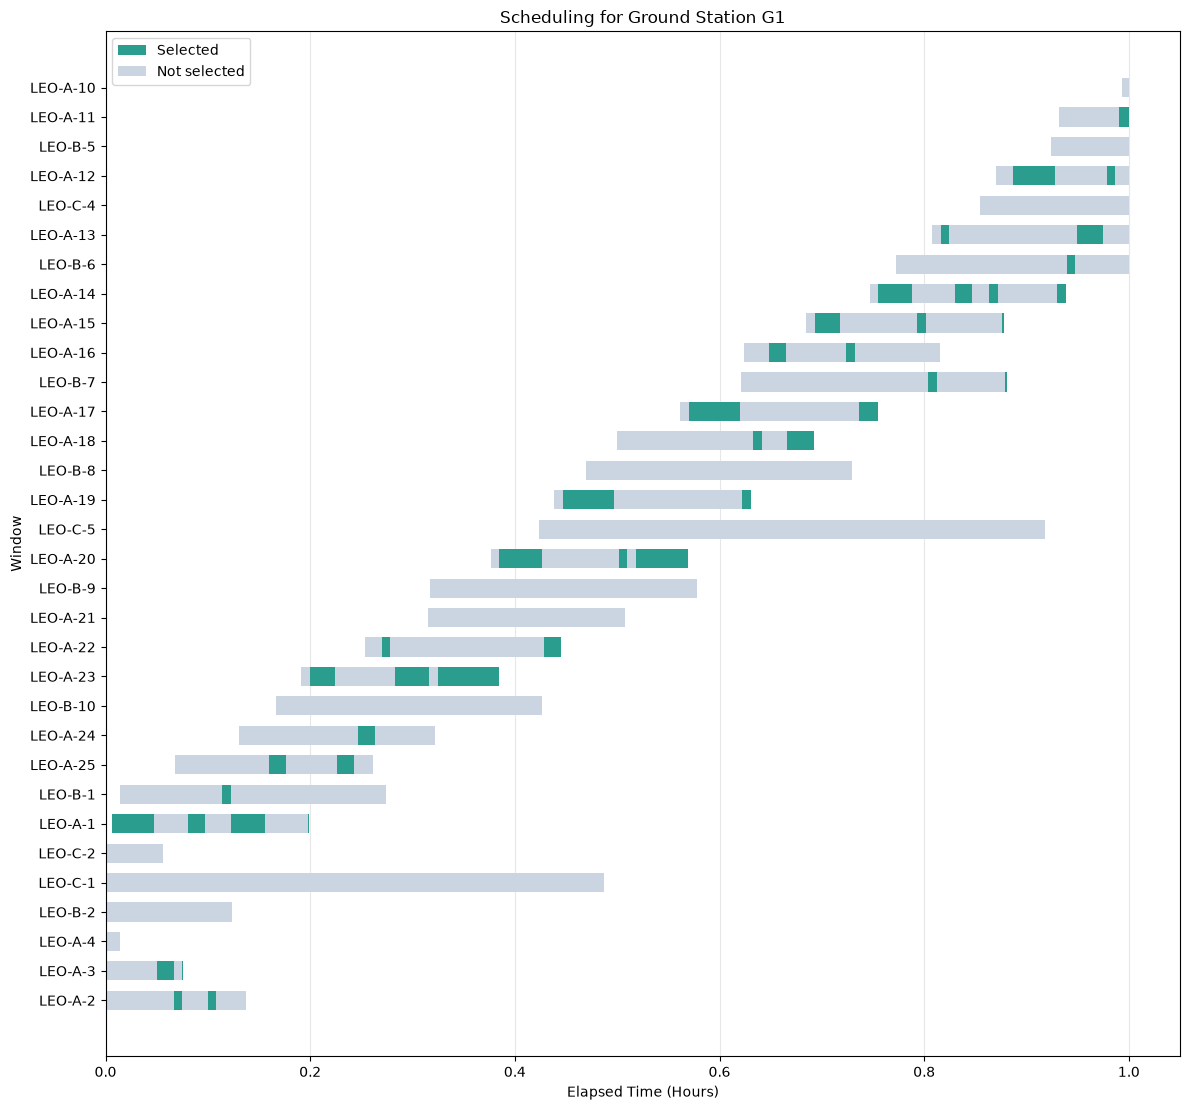

In [69]:
### GENERATED CODE GPT-6 LUNA VIA COPILOT

# Extract selected segments.
selected_windows = [
    window
    for window, decision_var in zip(windows, sol)
    if decision_var == 1
]

# Calculate payload downloaded.
payload_downloaded = np.array([window[4] for window in selected_windows]).sum()
print(f"Payload Downloaded: {round(payload_downloaded.item() / 10**6, 3)} TB")

# Group segments by their source window.
window_names = list(dict.fromkeys(
    window[0].rsplit("-s", 1)[0] for window in windows
))
window_positions = {
    name: position for position, name in enumerate(window_names)
}

# Plot each segment on its source window's row.
fig, ax = plt.subplots(figsize=(12, max(4, 0.35 * len(window_names))))

for segment_idx, (segment_name, start, end, _, _) in enumerate(windows):
    is_selected = sol[segment_idx] == 1
    window_name = segment_name.rsplit("-s", 1)[0]

    ax.barh(
        window_positions[window_name],
        (end - start) / 3600,
        left=start / 3600,
        height=0.65,
        color="#2a9d8f" if is_selected else "#cbd5e1",
    )

ax.set_yticks(list(window_positions.values()))
ax.set_yticklabels(window_names)
ax.set_xlabel("Elapsed Time (Hours)")
ax.set_ylabel("Window")
ax.set_title(f"Scheduling for Ground Station {station1.name}")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
ax.legend(handles=[
    Patch(facecolor="#2a9d8f", label="Selected"),
    Patch(facecolor="#cbd5e1", label="Not selected"),
])

fig.tight_layout()
plt.show()

### References

https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.milp.html

https://www.sciencedirect.com/science/article/abs/pii/S0305054814002809?via%3Dihub